# Is my NautilusTrader backtest too optimistic?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sarptandoven/queuetruth/blob/main/examples/notebooks/02_nautilus_too_optimistic.ipynb)

A backtest of a passive (limit-order) strategy is only as good as its answer to one question: *would this resting
order have filled?* On L2 data NautilusTrader cannot see the real queue, so its fill model guesses. This notebook
measures that guess against the exact answer from order-level data, and then fixes it.

The zoo models used here reproduce NautilusTrader's own fill logic and have been checked against the real engine:
fed the same L2 view and the same orders, `nautilus_trader` 1.231.0's `BacktestEngine` with
`FillModel(prob_fill_on_limit=1)` fills exactly the same orders as the zoo's `nt_prob_touch[p=1]` at 1 s, 10 s and
60 s on both Nasdaq days below (100% agreement; 2.0.0rc7 too), and `queue_position=True` agrees with
`nt_queue_l2` on 100% of orders on a delta feed. The harness and tables are in the repository's
`docs/RESULTS.md` (NautilusTrader cross-check).

| NautilusTrader configuration | zoo model |
|---|---|
| `FillModel(prob_fill_on_limit=1)` (the default) | `nt_prob_touch[p=1]` |
| `FillModel(prob_fill_on_limit=p)` | `nt_prob_touch[p=...]` |
| venue `queue_position=True` (L2 queue tracking) | `nt_queue_l2` (nautilus_trader 1.x rules) |

`nt_queue_l2` follows the 1.x queue rules. NautilusTrader 2.0 caps the queue ahead when the level shrinks, which
makes it slightly less pessimistic on a few orders a day (`docs/RESULTS.md`, NautilusTrader 2.0 re-run).

**Data.** Set the environment variable `QT_NB_DATASET` to an order-level dataset directory (Nasdaq ITCH, Databento
MBO, ...) holding at least two session dates, and this notebook measures your data; in a running Jupyter or Colab
kernel, run `%env QT_NB_DATASET=/path/to/dataset` before the first code cell. Without it the notebook uses
queuetruth's synthetic dataset and says so in every result. The stored outputs were produced on two public Nasdaq
TotalView-ITCH sample days (2019-12-30 and 2020-01-30, four liquid symbols each; source
[emi.nasdaq.com/ITCH](https://emi.nasdaq.com/ITCH/Nasdaq%20ITCH/), not redistributed here). Only aggregate
statistics are shown: no prices, no order-level rows. `queuetruth ingest` writes one session date per run, so the
two-day dataset is two ingests merged by the repository's `scripts/realdata/merge_datasets.py`:

```sh
queuetruth ingest --format itch --in 12302019.NASDAQ_ITCH50.gz --venue nasdaq --date 2019-12-30 \
    --symbols AAPL,MSFT,SPY,TSLA --out nasdaq-20191230
queuetruth ingest --format itch --in 01302020.NASDAQ_ITCH50.gz --venue nasdaq --date 2020-01-30 \
    --symbols AAPL,MSFT,SPY,TSLA --out nasdaq-20200130
python scripts/realdata/merge_datasets.py --out nasdaq-2d nasdaq-20191230 nasdaq-20200130
```

(The stored outputs used an ingest of the same two days from the order-level CSVs of an earlier prototype;
`docs/RESULTS.md` section 2 shows that raw-ITCH and CSV ingests of these days give identical books and fills.)

In [1]:
# Setup: on Colab (or anywhere queuetruth is missing) this installs it from PyPI; elsewhere it does nothing.
import importlib
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("queuetruth") is None:
    try:
        from IPython import get_ipython

        shell = get_ipython()
    except ImportError:
        shell = None
    if shell is not None:  # %pip lets Colab offer a restart when an already-imported package was upgraded
        shell.run_line_magic("pip", "install -q queuetruth pandas matplotlib")
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "queuetruth", "pandas", "matplotlib"])
    importlib.invalidate_caches()
if importlib.util.find_spec("queuetruth") is None or importlib.util.find_spec("queuetruth.frames") is None:
    raise RuntimeError(
        "this notebook needs queuetruth.frames (first released after queuetruth 0.1.1): pip install -U queuetruth"
    )

In [2]:
import json
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq

import queuetruth as qt
from queuetruth import frames

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.5, 3.6)})

WORK = Path("qt-notebooks") / "02_nautilus"
WORK.mkdir(parents=True, exist_ok=True)

env = os.environ.get("QT_NB_DATASET")
if env:
    DATA = Path(env)
else:
    DATA = WORK / "synth"
    if not (DATA / "manifest.json").exists():
        qt.fixtures_synth(str(DATA))
manifest = json.loads((DATA / "manifest.json").read_text())
instruments = pq.read_table(DATA / "instruments.parquet").to_pylist()
DATES = sorted({str(r["session_date"]) for r in instruments})
SYNTHETIC = manifest.get("validation_status") != "real_data"
LABEL = "SYNTHETIC data (numbers say nothing about a real venue)" if SYNTHETIC else f"{manifest['venue']} real data"
symbols = sorted({r["symbol"] for r in instruments})
print(f"{LABEL}: source format {manifest['source_format']}, {len(DATES)} session dates {DATES}")
print(f"symbols: {', '.join(symbols)}; validation_status {manifest['validation_status']}")

nasdaq real data: source format etcsv, 2 session dates ['2019-12-30', '2020-01-30']
symbols: AAPL, MSFT, SPY, TSLA; validation_status real_data


## 1. Place 3,000 shadow orders per day into the real queue

The shadows look like a passive market maker's quotes: at the touch (60%), one or two ticks behind (30%) or one
tick inside (10%), of 1 lot or the median order size, submitted uniformly between 5 minutes after the open and 10
minutes before the close, resting up to 5 minutes. The exact engine joins each one at the back of the real FIFO
queue at its price and follows every order ahead of it. Each shadow belongs to the session (instrument and date in
`instruments.parquet`) whose open-to-close window contains its submit time, which also holds for venues whose
session crosses UTC midnight.

In [3]:
N_PER_DAY = 3000
SHADOWS = WORK / "shadows.parquet"
samp = qt.sample_shadows({"dataset": {"path": str(DATA)}, "out": str(SHADOWS), "n": N_PER_DAY * len(DATES), "seed": 0})
spec = pq.read_table(SHADOWS)
windows = {}  # instrument_id -> [(open ns, close ns, session date)]
for r in instruments:
    m0 = r["midnight_utc_ns"]
    windows.setdefault(r["instrument_id"], []).append(
        (m0 + r["open_s"] * 10**9, m0 + r["close_s"] * 10**9, str(r["session_date"]))
    )
session = []
for iid, ts in zip(spec["instrument_id"].to_pylist(), pc.cast(spec["ts_submit"], "int64").to_pylist(), strict=True):
    hits = [d for lo, hi, d in windows[iid] if lo <= ts <= hi]
    assert len(hits) == 1, f"instrument {iid}: submit time {ts} lies in {len(hits)} sessions"
    session.append(hits[0])
session = pa.array(session)
per_day = {}
for d in DATES:
    p = WORK / f"shadows-{d}.parquet"
    pq.write_table(spec.filter(pc.equal(session, d)), p)  # keeps the qt.shadow_spec metadata
    per_day[d] = p
counts = {d: pq.read_metadata(p).num_rows for d, p in per_day.items()}
assert sum(counts.values()) == spec.num_rows
print(counts, "shadows by session date")

{'2019-12-30': 3000, '2020-01-30': 3000} shadows by session date


## 2. Run Nautilus's fill models and the bounds against exact truth

One zoo run per day, in faithful mode (each model reproduces its library's released behaviour, bugs included).
`fill_rate_bias` is the model's fill rate minus the exact fill rate by each horizon: positive means the backtest
fills orders the market would not have filled. `front_of_queue` (fill as soon as the price trades) and
`trade_through_only` (fill only when the price trades through) are the optimistic and pessimistic bounds.

Every model in one zoo run is scored on the same shadows. Only NautilusTrader models and the bounds run here: a
faithful hftbacktest model would drop each shadow on which hftbacktest aborts (its issue #312) from every model's
row, and the NautilusTrader numbers would then describe a sample chosen by another simulator's failure.

In [4]:
MODELS = ["nt_prob_touch[p=1]", "nt_queue_l2", "front_of_queue", "trade_through_only"]
boards = []
for d, p in per_day.items():
    z = qt.run_zoo(
        {
            "dataset": {"path": str(DATA)},
            "shadows": {"path": str(p)},
            "out": str(WORK / f"zoo-{d}"),
            "models": MODELS,
            "mode": "faithful",
            "seed": 0,
            "threads": 2,
        }
    )
    short = dict(zip(z.models, MODELS, strict=True))  # canonical id -> the name asked for
    lb = frames.leaderboard(z)
    assert z.n_excluded_hbt_312 == 0
    boards.append(lb.assign(date=d, n_shadows=z.n_shadows, model=lb["model_id"].map(short)))
board = pd.concat(boards, ignore_index=True)
HZ = {10**9: "1s", 10**10: "10s", 6 * 10**10: "60s"}


def hz(ns):
    """`1000000000` -> `1s`, `100000000` -> `100ms`."""
    ns = int(ns)
    return f"{ns // 10**9}s" if ns % 10**9 == 0 else f"{ns // 10**6}ms"


board = board[board["horizon_ns"].isin(list(HZ))].assign(horizon=lambda b: b["horizon_ns"].map(HZ))
print(LABEL)
exact = board.drop_duplicates(["date", "horizon"]).pivot(index="date", columns="horizon", values="exact_fill_rate")
print("exact fill rate (share of shadows filled by the horizon):")
(100 * exact[list(HZ.values())]).round(2)

nasdaq real data
exact fill rate (share of shadows filled by the horizon):


horizon,1s,10s,60s
date,,,
2019-12-30,11.03,48.43,75.00
2020-01-30,18.50,58.20,80.73


In [5]:
def cell(r):
    return f"{100 * r.fill_rate_bias:+.2f} [{100 * r.ci_lo:+.2f}, {100 * r.ci_hi:+.2f}]"


table = board.assign(bias=board.apply(cell, axis=1)).pivot(index="model", columns=["date", "horizon"], values="bias")
print(LABEL, "| fill-rate bias in percentage points, 95% block-bootstrap CI")
table[[(d, h) for d in DATES for h in HZ.values()]]

nasdaq real data | fill-rate bias in percentage points, 95% block-bootstrap CI


date                          2019-12-30                                                              2020-01-30                           \
horizon                               1s                      10s                     60s                     1s                      10s   
model                                                                                                                                       
front_of_queue      +3.13 [+2.63, +3.64]     +3.30 [+2.47, +4.14]    +1.43 [+1.01, +1.92]   +2.80 [+2.15, +3.55]     +2.03 [+1.51, +2.54]   
nt_prob_touch[p=1]  +3.13 [+2.63, +3.64]     +3.30 [+2.47, +4.14]    +1.43 [+1.01, +1.92]   +2.80 [+2.15, +3.55]     +2.03 [+1.51, +2.54]   
nt_queue_l2         -0.10 [-0.25, +0.00]     -0.77 [-0.98, -0.54]    -0.70 [-1.03, -0.38]   -0.10 [-0.25, +0.00]     -0.17 [-0.38, +0.04]   
trade_through_only  -5.97 [-7.71, -4.48]  -15.77 [-16.86, -14.63]  -10.13 [-12.00, -8.37]  -9.90 [-11.81, -8.21]  -12.93 [-13.80, -11.98]   

date                                      
horizon                              60s  
model                                     
front_of_queue      +0.93 [+0.50, +1.33]  
nt_prob_touch[p=1]  +0.93 [+0.50, +1.33]  
nt_queue_l2         -0.23 [-0.42, -0.07]  
trade_through_only  -6.57 [-7.49, -5.60]

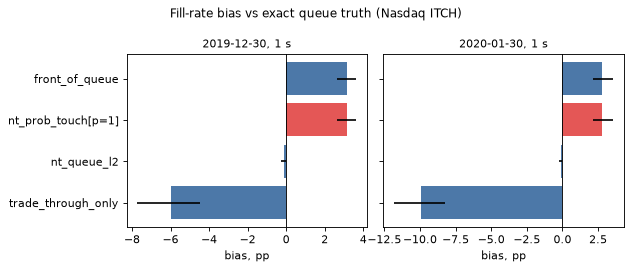

In [6]:
fig, axes = plt.subplots(1, len(DATES), sharey=True, figsize=(8, 3.4))
for ax, d in zip(axes if len(DATES) > 1 else [axes], DATES, strict=True):
    sub = board[(board["date"] == d) & (board["horizon"] == "1s")].sort_values("fill_rate_bias")
    err = [100 * (sub["fill_rate_bias"] - sub["ci_lo"]), 100 * (sub["ci_hi"] - sub["fill_rate_bias"])]
    colors = ["#e45756" if m.startswith("nt_prob_touch") else "#4c78a8" for m in sub["model"]]
    ax.barh(sub["model"], 100 * sub["fill_rate_bias"], xerr=err, color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{d}, 1 s", fontsize=10)
    ax.set_xlabel("bias, pp")
fig.suptitle(f"Fill-rate bias vs exact queue truth ({'synthetic' if SYNTHETIC else 'Nasdaq ITCH'})", fontsize=11)
fig.tight_layout()

## 3. Which orders does the default fill wrongly?

McNemar's discordant counts at the longest horizon (5 minutes): `c` orders the model fills and the exact replay
does not, `b` the reverse. A touch model can only err one way, because it fills every order whose price trades and
ignores the queue ahead, so `b` is zero. `n_leaderboard` is the shadows every row of the table above is scored on
(`n_excluded_hbt_312`, the shadows dropped because a faithful hftbacktest model aborted, is zero here because none
runs). By queue decile (exact queue ahead when the order went live), look at whether the error is confined to deep
queues.

In [7]:
nt = board[board["model"] == "nt_prob_touch[p=1]"].drop_duplicates("date")
print(LABEL)
cols = ["date", "n_shadows", "n_leaderboard", "n_excluded_hbt_312", "mcnemar_b", "mcnemar_c", "mcnemar_p_exact"]
print(nt[cols].to_string(index=False))

deciles = []
for d in DATES:
    err = frames.load_run(WORK / f"zoo-{d}")["zoo_errors"]
    sel = err[
        err["model_id"].str.startswith("nt_prob_touch")
        & (err["metric"] == "fill_rate_bias")
        & (err["horizon_ns"] == 10**9)
        & (err["stratum_kind"] == "queue_decile")
    ]
    deciles.append(sel.assign(date=d, decile=sel["stratum"].astype(int)))
dec = pd.concat(deciles)
print("\nnt_prob_touch[p=1] fill-rate bias at 1 s by queue decile, pp")
(100 * dec.pivot(index="decile", columns="date", values="value")).round(2)

nasdaq real data
      date  n_shadows  n_leaderboard  n_excluded_hbt_312  mcnemar_b  mcnemar_c  mcnemar_p_exact
2019-12-30       3000           3000                   0          0         19         0.000004
2020-01-30       3000           3000                   0          0         13         0.000244

nt_prob_touch[p=1] fill-rate bias at 1 s by queue decile, pp


date,2019-12-30,2020-01-30
decile,,
0,2.80,2.48
1,5.64,2.64
2,1.69,3.04
3,3.08,1.29
4,3.90,3.99
5,2.56,2.89
6,1.92,3.65
7,3.22,2.09
8,3.76,3.37


## 4. Fix it: calibrate `prob_fill_on_limit` and export a FillModel

Two fixes exist. With order-level data, NautilusTrader 2.0's own queue model fills the same orders as exact
replay (`docs/RESULTS.md`, NautilusTrader 2.0 re-run), so feed it order-level data if you have it. On L2 data,
either turn on `queue_position=True` (the `nt_queue_l2` row above) or keep the touch model and fit its fill
probability `p` against exact truth: train on the first day, test on the second, and export it only if it beats
the default `p = 1` out of sample.

The held-out evaluation scores the same test-day shadows as the zoo run above, so its `default` row repeats the
zoo's `nt_prob_touch[p=1]` numbers for that day, and the `fitted` row shows what the fit changes.

In [8]:
if len(DATES) < 2:
    print("one session date only: calibration needs a train and a test date; skipping")
else:
    cal = qt.calibrate(
        {
            "kind": "nt_touch",
            "family": "nt_prob_touch",
            "dataset": {"path": str(DATA)},
            "shadows": {"path": str(SHADOWS)},
            "out": str(WORK / "cal-nt"),
            "train": {"dates": [DATES[0]]},
            "test": {"dates": [DATES[1]]},
            "threads": 2,
        }
    )
    lo, hi = cal.ci_bootstrap
    print(LABEL)
    print(f"fitted {cal.param_name} = {cal.estimate:.3f} (bootstrap 95% CI {lo:.3f} .. {hi:.3f})")
    print(f"from {cal.n_events} touch events of {cal.n_shadows} train shadows; trust verdict: {cal.trust.verdict}")
    ho = frames.held_out(cal)
    ho = ho[ho["horizon_ns"].isin(list(HZ))].assign(horizon=lambda h: h["horizon_ns"].map(HZ))
    show = ho.pivot(index="arm", columns="horizon", values=["fill_rate_bias", "logloss"])
    print(f"held-out on {DATES[1]}: fitted vs default (p = 1); fill-rate bias as a fraction")
    print(show.reindex(columns=list(HZ.values()), level=1).round(4).to_string())
    print("beats default by horizon:", {hz(h): v for h, v in cal.trust.beats_default.items()})

nasdaq real data
fitted p = 0.287 (bootstrap 95% CI 0.273 .. 0.304)
from 4455 touch events of 1886 train shadows; trust verdict: exportable
held-out on 2020-01-30: fitted vs default (p = 1); fill-rate bias as a fraction
        fill_rate_bias                 logloss                
horizon             1s     10s     60s      1s     10s     60s
arm                                                           
default         0.0280  0.0203  0.0093  0.3868  0.2809  0.1289
fitted          0.0041 -0.0036 -0.0038  0.0324  0.0417  0.0196
beats default by horizon: {'100ms': 'better', '1s': 'better', '10s': 'better', '60s': 'better', '300s': 'better'}


The export writes the fitted value into a NautilusTrader snippet, with the provenance (data, dates, interval and
held-out result) as comments. If the fit had not beaten the default, `export` would refuse with `QT-CALIB-001`
instead of handing you a number that makes the backtest worse.

In [9]:
if len(DATES) >= 2:
    with warnings.catch_warnings(record=True) as notes:  # export reports its notes as warnings
        warnings.simplefilter("always")
        ex = qt.api.export(
            {"target": "nautilus", "calibration": {"path": str(WORK / "cal-nt")}, "out": str(WORK / "nt.py")}
        )
    print(ex.text)
    for n in notes:
        print("note:", n.message)

# queuetruth 0.1.1 | calibration 9d7e5bd2b05c7d9e | NautilusTrader API as documented at develop 5247ad5 (verify names
# for your version; newer builds expose FillModel under nautilus_trader.execution)
# nt_prob_touch fitted on 2019-12-30; held-out 2020-01-30; data: nasdaq (real_data, dataset 68913f7d28f1)
# fit: p = 0.286869 (nt_touch); 4455 events from 1886 shadows; bootstrap CI [0.272791, 0.30374]; profile CI [-, -]
# held-out: beats the default nt_prob_touch[mode=faithful;p=1] out of sample: better at 100ms, 1s, 10s, 60s, 5m
from nautilus_trader.backtest.models import FillModel
fill_model = FillModel(prob_fill_on_limit=0.286869)
# not fitted: prob_slippage, random_seed (set them as in your current FillModel)
# latency_model: not fitted (no latency calibration in this result); keep your own LatencyModel
# queue_position=True and trade_execution=True on the venue config when the fit was queue-gated (no)

note: prob_fill_on_limit is a per-touch Bernoulli probability: it is not portable

## What to take away

- In the stored Nasdaq outputs the NautilusTrader default overfills at every horizon and in every queue decile,
  most at 1 to 10 s (+3.13 pp at 1 s on 2019-12-30 and +2.80 pp on 2020-01-30, the figures and intervals of the
  faithful-mode table in `docs/RESULTS.md`), and every disagreement is a fill the real queue did not give. A
  strategy whose edge depends on short-horizon passive fills inherits that optimism directly.
- `queue_position=True` (`nt_queue_l2`) removes most of it on L2 data; a fitted `prob_fill_on_limit` removes much
  of it while keeping the touch model.
- The decisive check is your own fills:
  [04: Score your simulator against your fills](04_score_simulator_vs_fills.ipynb) scores a simulator against a
  live order log, order by order.

These are small orders on four very liquid US stocks on two days; the repository's `docs/RESULTS.md` extends the
comparison to 36 more names, where the default overfills most on deep-queue names.